<h2 style="font-weight:600;color:#4f7a9b">Clustering Text Documents using k-means</h2>

<h3 style="font-weight:600;color:#4f7a9b">1 | Loading Text Data</h3>

The `20 newsgroups text dataset` contains 18,000 posts on 20 topics. We only take a subset of 4 categories (about 3,400 documents). We also remove metadata such as **headers**, **footers** and **quotes** to focus on the clustering problem.


In [33]:
import numpy as np
from sklearn.datasets import fetch_20newsgroups

categories = ["alt.atheism", "talk.religion.misc", "comp.graphics", "sci.space"]
dataset = fetch_20newsgroups(
    remove=("headers", "footers", "quotes"), subset="all", categories=categories, shuffle=True, random_state=42
)

labels = dataset.target
unique_labels, category_sizes = np.unique(labels, return_counts=True)
true_k = unique_labels.shape[0]

print(f"{len(dataset.data)} documents - {true_k} categories")

3387 documents - 4 categories


<h3 style="font-weight:600;color:#4f7a9b">2 | Quantifying the Quality of Clustering Results</h3>

In [34]:
from collections import defaultdict
from time import time

from sklearn import metrics

evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)

    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(metrics.adjusted_rand_score(labels, km.labels_))
        scores["Silhouette Coefficient"].append(metrics.silhouette_score(X, km.labels_, sample_size=2000))

    train_times = np.asarray(train_times)
    print(f"Clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s")

    evaluation = {"estimator": name, "train_time": train_times.mean()}
    evaluation_std = {"estimator": name, "train_time": train_times.std()}

    for score_name, score_values in scores.items():
        mean_score = np.mean(score_values)
        std_score = np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score

    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)

<h3 style="font-weight:600;color:#4f7a9b">3 | K-means Clustering on Text Features</h3>

Methods for feature extraction:
- **TfidfVectorizer**<br/>
    Uses an in-memory vocabulary (Python dict) to map the most frequent words -> feature indices.<br/>
    This creates a word occurence frequency matrix.<br/>
    The word frequencies are then reweighted using the IDF vector colected over the corpus.

- **HashingVectorizer**<br/>
    Hashes word occurences, to a fixed dimensional space.<br/>
    The word count vectors are then normalized to each have l2-norm equal to one.

<h3 style="font-weight:600;color:#4f7a9b">4 | Feature Extraction using TfidfVectorizer</h3>

`max_df=0.5` : ignore terms that appear in **more** than 50% of the documents.<br/>
`min_df=5`   : ignore terms that have a frequency of occurence **less** than 5 times.<br/>

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_df=0.5, min_df=5, stop_words="english")
t0 = time()
X_tfidf = vectorizer.fit_transform(dataset.data)

print(f"Vectorization done in {time()-t0:.3f} s")
print(f"n_samples: {X_tfidf.shape[0]}, n_features: {X_tfidf.shape[1]}")

Vectorization done in 0.422 s
n_samples: 3387, n_features: 7929


To quantify the sparsity of the resulting matrix as a fraction:

$$ \frac{Non-zero \ entries}{Total \ number \ of \ elements}$$

In [36]:
print(f"Around {X_tfidf.nnz / np.prod(X_tfidf.shape):.1%} of the entries are non-zero.")

Around 0.7% of the entries are non-zero.


<h3 style="font-weight:600;color:#4f7a9b">5 | Clustering Sparse Data with k-means</h3>

<span style="font-weight:600;color:#4f7a9b">PROBLEM</span><br/>
Text vectorized using the **Bag of Words** approach, can lead to sparse high-dimensional data and as a result K-means may initialze centroids on **extemely isolated data points**, leading to highly **imbalanced clusters**:

In [37]:
from sklearn.cluster import KMeans

for seed in range(5):
    kmeans = KMeans(n_clusters=true_k, max_iter=100, n_init=1, random_state=seed).fit(X_tfidf)
    cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
    print(f"Number of elements assigned to each cluster: {cluster_sizes}")

print()
print(f"True number of documents in each category according to the class labels: {category_sizes}")

Number of elements assigned to each cluster: [ 481  675 1785  446]
Number of elements assigned to each cluster: [1689  638  480  580]
Number of elements assigned to each cluster: [   1    1    1 3384]
Number of elements assigned to each cluster: [1887  311  332  857]
Number of elements assigned to each cluster: [ 291  673 1771  652]

True number of documents in each category according to the class labels: [799 973 987 628]


<span style="font-weight:600;color:#4f7a9b">SOLUTION</span><br/>
Increase the number of independent random initializations `n_init`

In [38]:
kmeans = KMeans(n_clusters=true_k, max_iter=100, n_init=5)

fit_and_evaluate(kmeans, X_tfidf, name="KMeans\non tf-idf vectors")

Clustering done in 0.19 ± 0.03 s
Homogeneity: 0.349 ± 0.010
Completeness: 0.398 ± 0.009
V-measure: 0.372 ± 0.009
Adjusted Rand-Index: 0.203 ± 0.017
Silhouette Coefficient: 0.007 ± 0.001


<h3 style="font-weight:600;color:#4f7a9b">6 | Performing Dimensionality Reduction with LSA</h3>

In [39]:
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

lsa = make_pipeline(TruncatedSVD(n_components=100), Normalizer(copy=False))
t0 = time()
X_lsa = lsa.fit_transform(X_tfidf)
explained_variance = lsa[0].explained_variance_ratio_.sum()

print(f"LSA done in {time()-t0:.3f} s")
print(f"Explained variance of the SVD step: {explained_variance * 100:.1f}%")

LSA done in 0.503 s
Explained variance of the SVD step: 18.4%


In [40]:
kmeans = KMeans(n_clusters=true_k, max_iter=100, n_init=1)
fit_and_evaluate(kmeans, X_lsa, name="KMeans\nwith LSA on tf-idf vectors")

Clustering done in 0.02 ± 0.01 s
Homogeneity: 0.404 ± 0.002
Completeness: 0.429 ± 0.010
V-measure: 0.416 ± 0.004
Adjusted Rand-Index: 0.306 ± 0.009
Silhouette Coefficient: 0.030 ± 0.000


In [41]:
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(n_clusters=true_k, n_init=1, init_size=1000, batch_size=1000)
fit_and_evaluate(minibatch_kmeans, X_lsa, name="MiniMatchKMeans\nwith LSA on tf-idf vectors")

Clustering done in 0.02 ± 0.01 s
Homogeneity: 0.376 ± 0.049
Completeness: 0.385 ± 0.041
V-measure: 0.380 ± 0.045
Adjusted Rand-Index: 0.327 ± 0.035
Silhouette Coefficient: 0.029 ± 0.002


<h3 style="font-weight:600;color:#4f7a9b">7 | Top Terms per Cluster</h3>

In [42]:
original_space_centroids = lsa[0].inverse_transform(kmeans.cluster_centers_)
order_centroids = original_space_centroids.argsort()[:, ::-1]
terms = vectorizer.get_feature_names_out()

for i in range(true_k):
    print(f"Cluster {i}: ", end="")

    for ind in order_centroids[i, :10]:
        print(f"{terms[ind]} ", end="")

    print()

Cluster 0: space launch orbit nasa shuttle earth moon like mission satellite 
Cluster 1: just think don know like time ve good does say 
Cluster 2: god people jesus believe don bible say think christian religion 
Cluster 3: thanks graphics image program files file know looking help format 


<h3 style="font-weight:600;color:#4f7a9b">8 | HashingVectorizer</h3>

In [43]:
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer

lsa_vectorizer = make_pipeline(
    HashingVectorizer(stop_words="english", n_features=50_000),
    TfidfTransformer(),
    TruncatedSVD(n_components=100, random_state=0),
    Normalizer(copy=False),
)

t0 = time()
X_hashed_lsa = lsa_vectorizer.fit_transform(dataset.data)
print(f"Vectorization done in {time()-t0:.3f} s")

Vectorization done in 1.931 s


In [44]:
fit_and_evaluate(kmeans, X_hashed_lsa, name="KMeans\nwith LSA on hashed vectors")

Clustering done in 0.02 ± 0.00 s
Homogeneity: 0.392 ± 0.008
Completeness: 0.437 ± 0.011
V-measure: 0.413 ± 0.009
Adjusted Rand-Index: 0.327 ± 0.022
Silhouette Coefficient: 0.029 ± 0.002


In [45]:
fit_and_evaluate(minibatch_kmeans, X_hashed_lsa, name="MiniBatchKMeans\nwith LSA on hashed vectors")

Clustering done in 0.03 ± 0.02 s
Homogeneity: 0.349 ± 0.048
Completeness: 0.365 ± 0.043
V-measure: 0.356 ± 0.045
Adjusted Rand-Index: 0.309 ± 0.037
Silhouette Coefficient: 0.024 ± 0.004


<h3 style="font-weight:600;color:#4f7a9b">Clustering Evaluation Summary</h3>

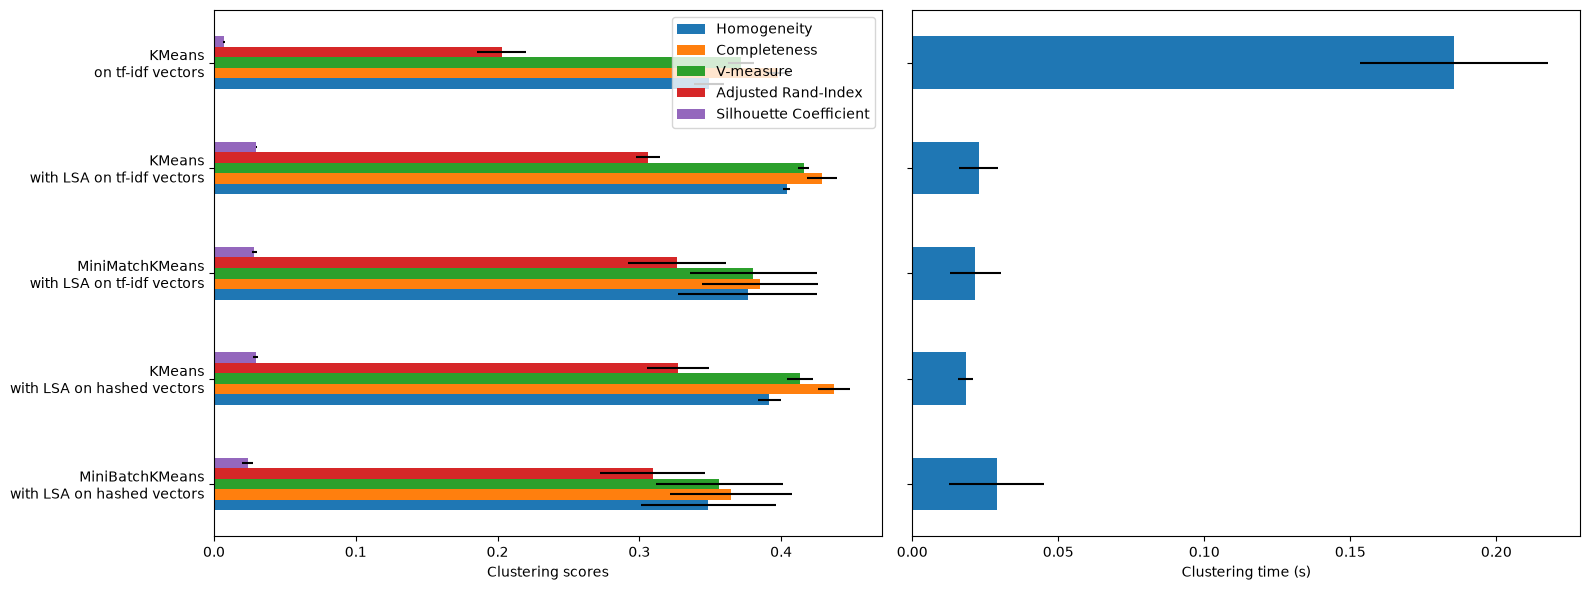

In [47]:
import matplotlib.pyplot as plt
import pandas as pd

fig, (ax0, ax1) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6), sharey=True)

df = pd.DataFrame(evaluations[::-1]).set_index("estimator")
df_std = pd.DataFrame(evaluations_std[::-1]).set_index("estimator")

df.drop(["train_time"], axis="columns").plot.barh(ax=ax0, xerr=df_std)
ax0.set_xlabel("Clustering scores")
ax0.set_ylabel("")

df["train_time"].plot.barh(ax=ax1, xerr=df_std["train_time"])
ax1.set_xlabel("Clustering time (s)")
plt.tight_layout()